In [13]:
# import the libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [14]:
# import the dataset
# pull data from csv file
data = pd.read_csv('heart.csv')

# ส่วนที่ 1: Feature Engineering

## 1. Observe the 
- ตรวจสอบโครงสร้างและขนาดของชุดข้อมูล

- ตรวจสอบจำนวนระเบียน จำนวนตัวแปร และชนิดข้อมูลของแต่ละตัวแปร

- ตรวจสอบและจัดการข้อมูลที่สูญหาย (Missing Values)

In [15]:
# show data information
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [16]:
# show data shape
data.shape

(918, 12)

In [ ]:
print(data.head())
data.isnull().sum()

   Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR  \
0   40   M           ATA        140          289          0     Normal    172   
1   49   F           NAP        160          180          0     Normal    156   
2   37   M           ATA        130          283          0         ST     98   
3   48   F           ASY        138          214          0     Normal    108   
4   54   M           NAP        150          195          0     Normal    122   

  ExerciseAngina  Oldpeak ST_Slope  HeartDisease  
0              N      0.0       Up             0  
1              N      1.0     Flat             1  
2              N      0.0       Up             0  
3              Y      1.5     Flat             1  
4              N      0.0       Up             0  
              Age   RestingBP  Cholesterol   FastingBS       MaxHR  \
count  918.000000  918.000000   918.000000  918.000000  918.000000   
mean    53.510893  132.396514   198.799564    0.233115  136.809368 

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

In [18]:
data.dtypes

Age                 int64
Sex                object
ChestPainType      object
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG         object
MaxHR               int64
ExerciseAngina     object
Oldpeak           float64
ST_Slope           object
HeartDisease        int64
dtype: object

## 2. Preprocess numeric data
- ระบุตัวแปรที่เป็นข้อมูลตัวเลข
- เลือกและดำเนินการเตรียมข้อมูลตัวเลขด้วยวิธีที่เหมาะสม

In [ ]:
print(data.describe())

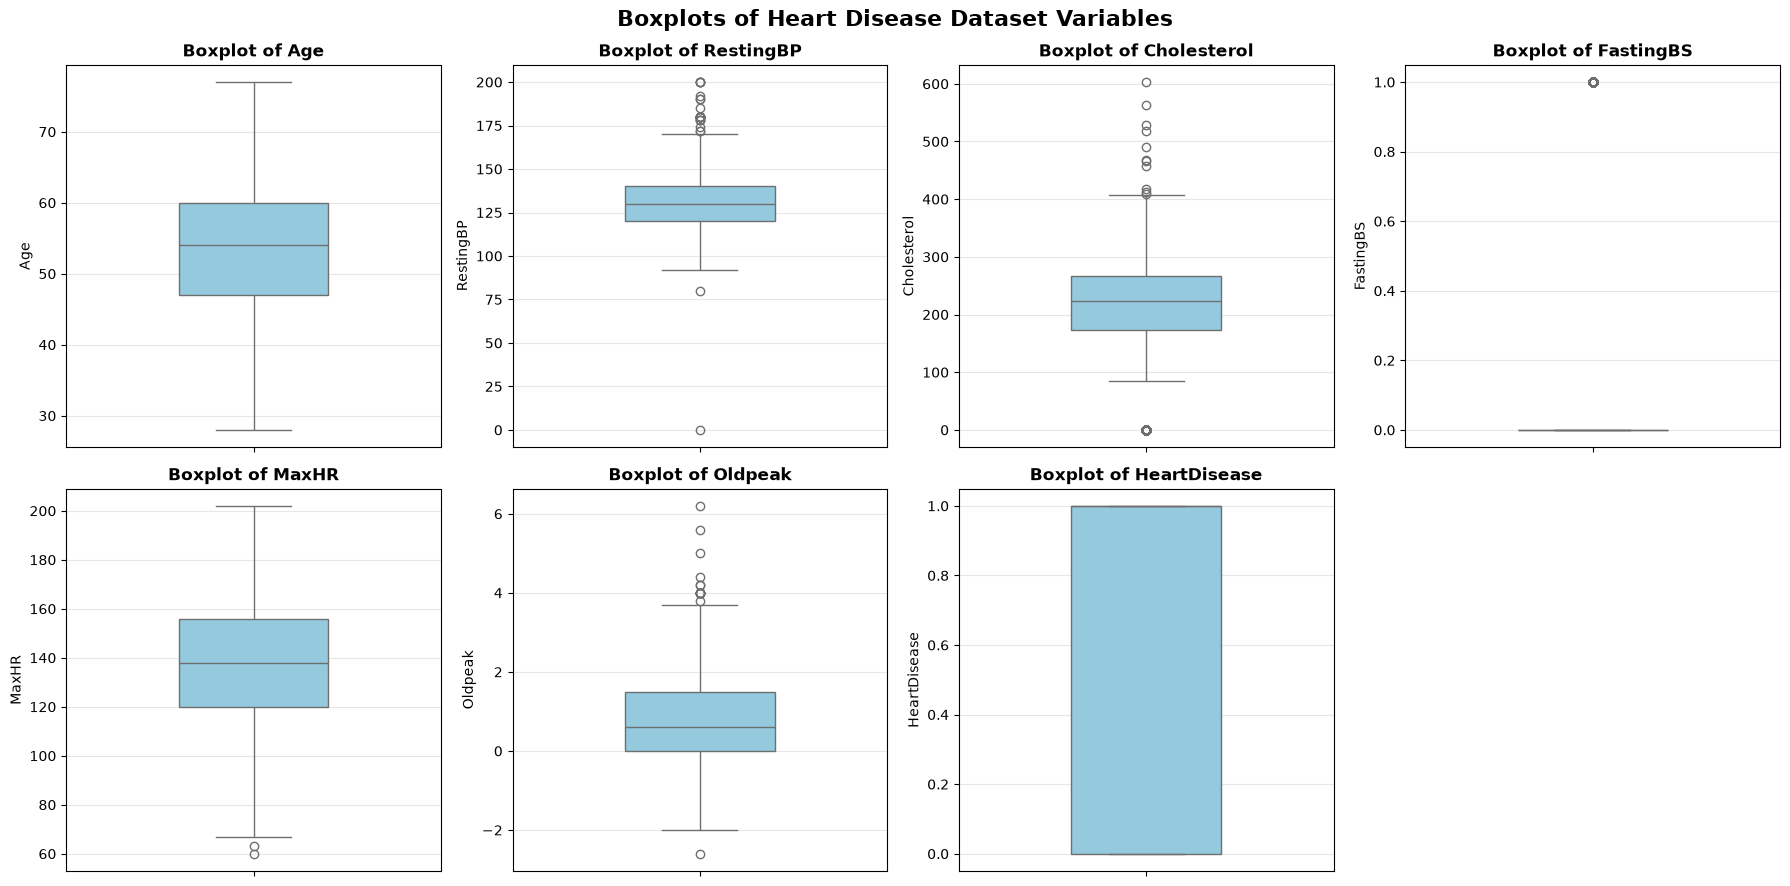

In [19]:
# Check the data type of the target variable by Box Plot
# AI Prompt: เขียน box plot ของแต่ละตัวแปร Age, RestingBP, Cholesterol, FastingBS, MaxHR, Oldpeak,HeartDisease อยู่ในภาพเดียวกัน

# โหลดข้อมูล
df = pd.read_csv("heart.csv")

# กำหนดตัวแปรที่ต้องการ
numeric_cols = [
    'Age', 'RestingBP', 'Cholesterol',
    'FastingBS', 'MaxHR', 'Oldpeak',
    'HeartDisease'
]

# สร้างกราฟ 2 แถว 4 คอลัมน์
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

# วนลูปสร้าง Boxplot
for i, col in enumerate(numeric_cols):
    sns.boxplot(
        y=df[col],
        ax=axes[i],
        color='skyblue',
        width=0.4
    )

    axes[i].set_title(
        f'Boxplot of {col}',
        fontsize=12,
        fontweight='bold'
    )
    axes[i].set_ylabel(col)
    axes[i].grid(axis='y', alpha=0.3)

# ซ่อนช่องที่ไม่ได้ใช้งาน
for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])

# ชื่อกราฟหลัก
fig.suptitle(
    'Boxplots of Heart Disease Dataset Variables',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()


In [20]:
# Number is Age, RestingBP, Cholesterol, FastingBS, MaxHR, Oldpeak,HeartDisease

## 3. Preprocess categorical data
- ระบุตัวแปรที่เป็นข้อมูลประเภทหมวดหมู่

- เลือกและดำเนินการแปลงข้อมูลหมวดหมู่ให้อยู่ในรูปแบบตัวเลขด้วยวิธีที่เหมาะสม

In [21]:
"""
mapping = {
    'Iris-setosa': 0,
    'Iris-versicolor': 1,
    'Iris-virginica': 2
}

df_main['iris_class'] = df_main['iris_class'].map(mapping)
df_main.head()
"""

"\nmapping = {\n    'Iris-setosa': 0,\n    'Iris-versicolor': 1,\n    'Iris-virginica': 2\n}\n\ndf_main['iris_class'] = df_main['iris_class'].map(mapping)\ndf_main.head()\n"

## 4. Separate all data to Training data and Test data
- แยกตัวแปรอิสระ (Features) ออกจากตัวแปรเป้าหมาย (Target)

- แบ่งข้อมูลเป็นชุดฝึกสอน (Training Set) และชุดทดสอบ (Test Set) ด้วยสัดส่วนที่เหมาะสม

- กำหนด random_state เพื่อให้สามารถทำซ้ำการทดลองได้

# ส่วนที่ 2: Classification Modeling

## 5. Decision Tree
- สร้างและฝึกสอนแบบจำลอง Decision Tree ด้วยชุดข้อมูลฝึกสอน

- ประเมินประสิทธิภาพของแบบจำลองด้วยชุดข้อมูลทดสอบ

In [ ]:
"""
from sklearn import tree

# 1. เทรนโมเดลด้วย DecisionTreeClassifier
clf = DecisionTreeClassifier(max_depth=5, random_state=42)
clf.fit(X_train, y_train)

plt.figure(figsize=(30, 20))  
tree.plot_tree(
    clf,
    feature_names=['m_radius', 'm_texture', 'm_perimeter', 'm_area', 'm_smoothness',
                   'm_compactness', 'm_concavity', 'm_concave_points', 'm_symmetry', 
                   'm_fractal_dimension', 'se_radius', 'se_texture', 'se_perimeter', 
                   'se_area', 'se_smoothness', 'se_compactness', 'se_concavity',
                   'se_concave_points', 'se_symmetry', 'se_fractal_dimension', 
                   'w_radius', 'w_texture', 'w_perimeter', 'w_area', 'w_smoothness', 
                   'w_compactness', 'w_concavity', 'w_concave_points', 'w_symmetry', 
                   'w_fractal_dimension'],
    class_names=['B', 'M'],
    filled=True
)
plt.show()
"""

In [ ]:
"""
#-- Dependent variables
list_accuracy = []
list_precision = []
list_recall = []
list_f1 = []

#-- Independent variables
list_max_depth = []

#-- Selected algorithms
criterion = 'gini'
spliter = 'best'
#criterion = 'entropy'
#spliter = 'random'

for i in range(5, 30, 2):
    clf = tree.DecisionTreeClassifier(criterion=criterion, splitter=spliter ,max_depth=i)
    scoring = ['accuracy', 'precision', 'recall', 'f1']
    scores = cross_validate(clf, X_cross, y_cross, cv=5, scoring=scoring)
    
    list_accuracy.append(np.mean(scores['test_accuracy']))
    list_precision.append(np.mean(scores['test_precision']))
    list_recall.append(np.mean(scores['test_recall']))
    list_f1.append(np.mean(scores['test_f1'])) 
    list_max_depth.append(i)

metrics = ["Accuracy", "Precision", "Recall", "F1"]
data_lists = [list_accuracy, list_precision, list_recall, list_f1]

fig, axes = plt.subplots(1, 4, figsize=(30, 5))
for ax, metric, data in zip(axes, metrics, data_lists):
    ax.plot(list_max_depth, data)
    ax.grid()
    ax.set_title(metric)
    ax.set_xlabel("max_depth")
    ax.set_ylabel(metric)

    ax.xaxis.set_major_locator(ticker.MultipleLocator(1))
    
"""

## 6. Random Forest
- สร้างและฝึกสอนแบบจำลอง Random Forest ด้วยชุดข้อมูลฝึกสอน

- ประเมินประสิทธิภาพของแบบจำลองด้วยชุดข้อมูลทดสอบ

In [ ]:
"""
#-- Dependent variables
list_accuracy = []
list_precision = []
list_recall = []
list_f1 = []

#-- Independent variables
list_max_depth = []

#-- Selected algorithms
criterion = 'gini'
#criterion = 'entropy'

for i in range(5, 10):
    clf = RandomForestClassifier(n_estimators=i, criterion=criterion)
    scoring = ['accuracy', 'precision', 'recall', 'f1']
    scores = cross_validate(clf, X_cross, y_cross, cv=5, scoring=scoring)
    
    list_accuracy.append(np.mean(scores['test_accuracy']))
    list_precision.append(np.mean(scores['test_precision']))
    list_recall.append(np.mean(scores['test_recall']))
    list_f1.append(np.mean(scores['test_f1'])) 
    list_max_depth.append(i)

metrics = ["Accuracy", "Precision", "Recall", "F1"]
data_lists = [list_accuracy, list_precision, list_recall, list_f1]

fig, axes = plt.subplots(1, 4, figsize=(30, 5))
for ax, metric, data in zip(axes, metrics, data_lists):
    ax.plot(list_max_depth, data)
    ax.grid()
    ax.set_title(metric)
    ax.set_xlabel("max_depth")
    ax.set_ylabel(metric)

    ax.xaxis.set_major_locator(ticker.MultipleLocator(1))
    
"""

In [ ]:
"""
clf = RandomForestClassifier(n_estimators=15, criterion='gini', max_depth=40)
clf.fit(X_cross, y_cross)
y_pred = clf.predict(X_final)

target_names = ['class 0', 'class 1']
print(classification_report(y_final, y_pred, target_names=target_names, digits=5))

cm = confusion_matrix(y_final, y_pred)
cm_display = ConfusionMatrixDisplay(cm).plot()
"""

## 7. Gradient Boost Trees
- สร้างและฝึกสอนแบบจำลอง Gradient Boost Tree ด้วยชุดข้อมูลฝึกสอน

- ประเมินประสิทธิภาพของแบบจำลองด้วยชุดข้อมูลทดสอบ

In [ ]:
"""
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

#---------- Load data ----------#
X_train = pd.read_csv('X_train.csv')
X_test = pd.read_csv('X_test.csv')

y_train = pd.read_csv('y_train.csv').squeeze()
y_test = pd.read_csv('y_test.csv').squeeze()

#---------- Parameter tuning ----------#
param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 0.5],
    'max_depth': [3, 5]
}

grid = GridSearchCV(
    estimator=GradientBoostingClassifier(
        random_state=42
    ),
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

grid.fit(X_train, y_train)

# Best model
best_gb = grid.best_estimator_

print("Best Parameters")
print(grid.best_params_)

print(f"Best CV F1 Score: {grid.best_score_:.4f}")

#---------- Predict ----------#
y_pred = best_gb.predict(X_test)

# Metrics
print("\n===== Test Result =====")
print(f"Accuracy  : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision : {precision_score(y_test, y_pred):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score  : {f1_score(y_test, y_pred):.4f}")

#---------- Confusion Matrix ----------#
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No', 'Yes']
)

disp.plot(cmap='Blues')
plt.title('Gradient Boosting Confusion Matrix')
plt.show()
"""

## 8. Model Comparison and Selection
- เปรียบเทียบประสิทธิภาพของแบบจำลองทั้ง 3 วิธีด้วยตัวชี้วัดที่เหมาะสม

- เลือกแบบจำลองที่มีประสิทธิภาพดีที่สุด พร้อมอธิบายเหตุผลประกอบการตัดสินใจ